# Qiskit Fall Fest 2026 - Workshop

Neste notebook vamos montar circuitos quânticos com o Qiskit, conhecer as principais portas e rodar nossos circuitos em simuladores, inclusive um que imita o ruído de um computador quântico real da IBM.

## 0. Preparando o ambiente

In [ ]:
!pip install -q qiskit qiskit-aer qiskit-ibm-runtime pylatexenc

In [ ]:
from qiskit import QuantumCircuit

from qiskit_aer import AerSimulator

from qiskit.visualization import plot_histogram

In [ ]:
simulador = AerSimulator()

## 1. Nosso primeiro circuito

Um bit é 0 ou 1. Um qubit também pode estar numa **superposição** dos dois. Uma forma simples de imaginar o qubit é como uma seta num círculo:

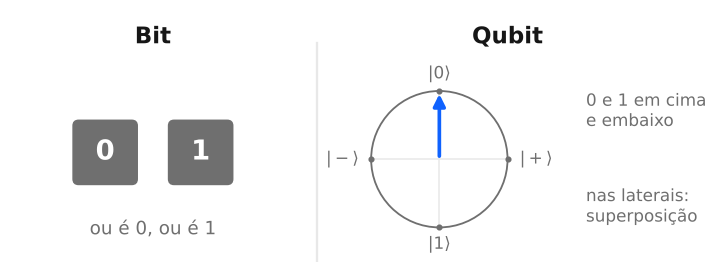

Todo qubit começa no estado **0**. Vamos criar um circuito com 1 qubit e só medir.

Agora rodamos o circuito no simulador. `shots` é quantas vezes o circuito é executado.

## 2. Como ler um circuito

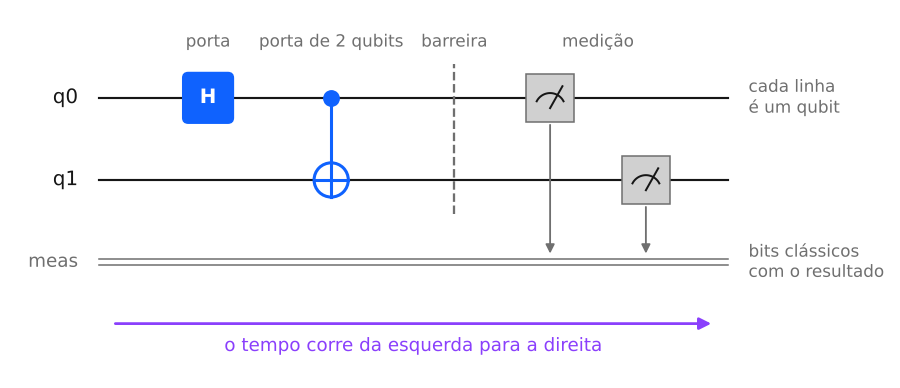

- Cada linha horizontal é um qubit (`q`), de cima para baixo: `q0`, `q1`, `q2`...
- O tempo corre da **esquerda para a direita**: as portas são aplicadas nessa ordem.
- A linha tracejada (barreira) serve para separar visualmente as partes do circuito.
- O símbolo do medidor é a medição, que transforma o qubit em um bit clássico (0 ou 1).

No resultado, o Qiskit escreve os bits **da direita para a esquerda**: se o resultado for `'01'`, o bit da direita é o `q0`.

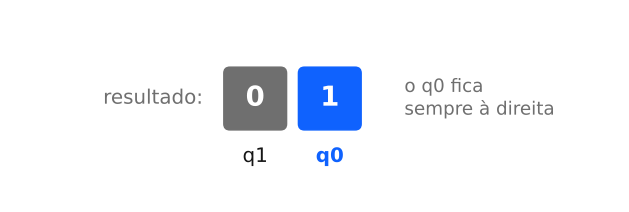

## 3. Portas de um qubit

### Porta X

Inverte o qubit: 0 vira 1, e 1 vira 0.

É o "NOT" quântico.

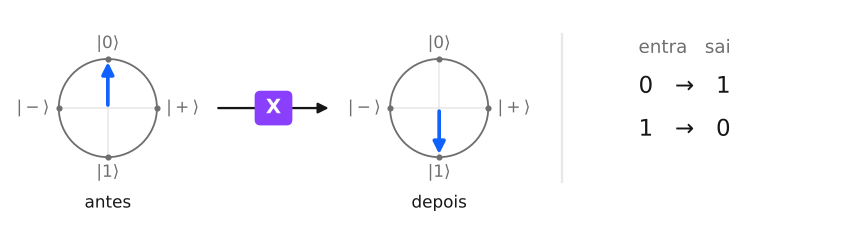

### Porta H (Hadamard)

Coloca o qubit em **superposição**: ao medir, metade das vezes dá 0 e metade dá 1.

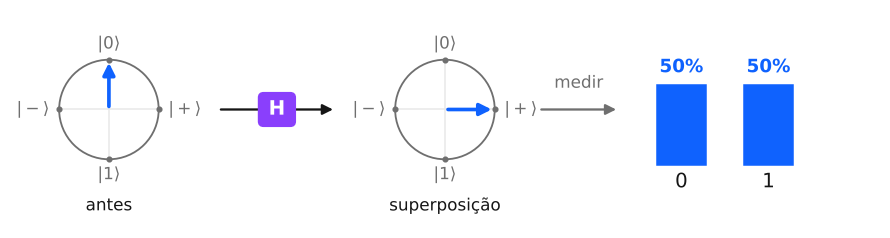

Experimente rodar a célula de cima de novo: os números mudam um pouco, porque cada medição é aleatória.

### Porta Z

A porta Z muda a **fase** do qubit. Sozinha, ela não muda o que medimos:

Mas a fase faz diferença quando há **interferência**. Compare os dois circuitos abaixo.

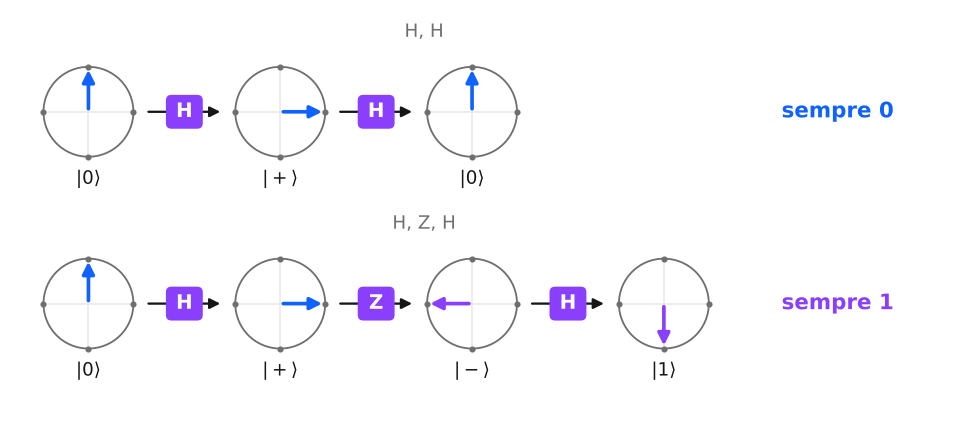

Primeiro, duas Hadamards seguidas: a segunda desfaz a primeira.

Agora com uma Z no meio:

A Z mudou a fase da superposição e, na segunda Hadamard, os "caminhos" interferiram de outro jeito: o resultado passou a ser sempre 1.

## 4. Portas de dois qubits

### CNOT

Tem um qubit de **controle** (bolinha) e um **alvo** (⊕). Se o controle for 1, o alvo é invertido. Se for 0, nada acontece.

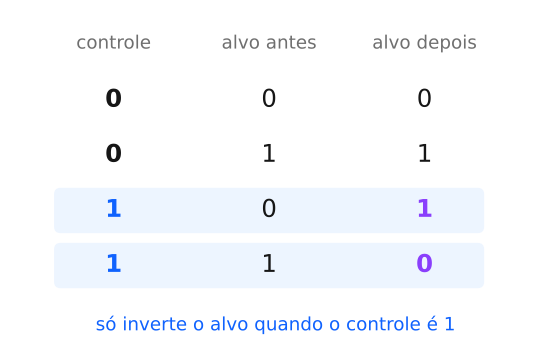

Com o controle em 1:

### SWAP

Troca os estados de dois qubits.

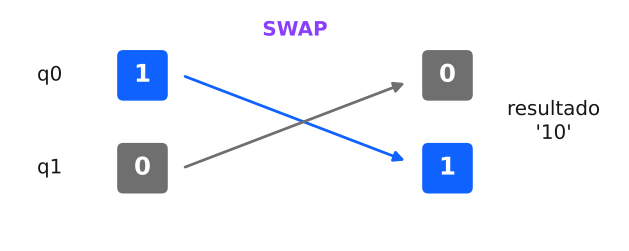

O 1 estava no `q0` e passou para o `q1`, enquanto o 0 do `q1` passou para o `q0`.

## 5. "Hello World" quântico: Estado de Bell (Φ+)

Uma Hadamard seguida de uma CNOT, criando um **emaranhamento** com esses dois qubits.

Só aparecem `00` e `11`. Cada qubit sozinho é aleatório, mas os dois sempre concordam.

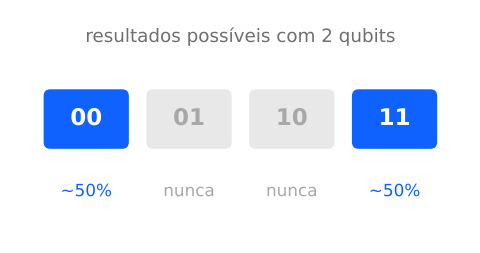

## 6. Estado GHZ

A mesma ideia do Bell, só que agora com 3 qubits.

Só aparecem `000` e `111`: ou todos dão 0, ou todos dão 1.

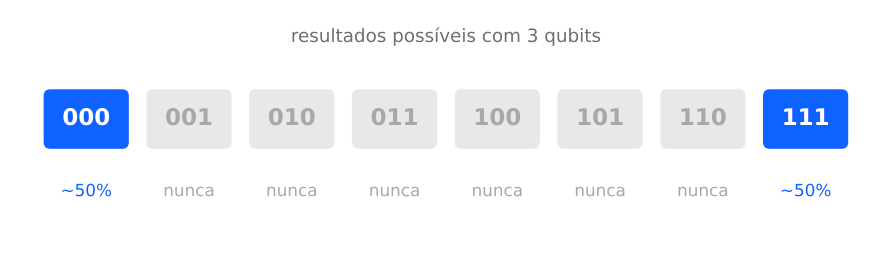

Experimente: mude `n` para criar um GHZ com mais qubits.

In [ ]:
n = 5

ghz_n = QuantumCircuit(n)

ghz_n.h(0)

for i in range(n - 1):
    ghz_n.cx(i, i + 1)

ghz_n.measure_all()

ghz_n.draw("mpl")

## 7. Qiskit Patterns

Todo programa quântico segue 4 passos:

1. **Mapear** o problema para um circuito
2. **Otimizar** o circuito para o hardware
3. **Executar** no computador quântico
4. **Pós-processar** os resultados

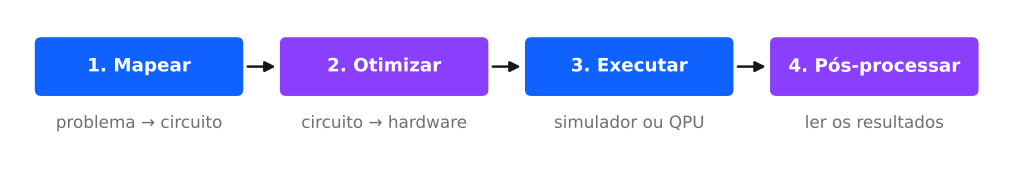

Vamos seguir esses passos com o estado de Bell, agora num simulador que imita um computador quântico real.

## 8. Simulando um computador quântico real

Os computadores quânticos reais têm **ruído**. O Qiskit tem backends "falsos" que imitam o ruído de computadores da IBM e rodam aqui mesmo, sem conta e sem fila.

Vamos usar o `FakeFez`, que imita o computador `ibm_fez`.

In [ ]:
from qiskit_ibm_runtime.fake_provider import FakeFez

from qiskit.transpiler import generate_preset_pass_manager

In [ ]:
backend = FakeFez()

### Passo 1: Mapear

O circuito é o mesmo estado de Bell que montamos antes.

### Passo 2: Otimizar

O computador real só entende algumas portas e nem todos os qubits estão conectados entre si. O transpiler reescreve o circuito para o hardware escolhido.

### Passo 3: Executar

Rodamos o circuito otimizado no backend falso, do mesmo jeito que no simulador.

### Passo 4: Pós-processar

In [ ]:
plot_histogram([contagens_bell, contagens_ruido], legend=["Simulador ideal", "Simulador com ruído"])

Com ruído aparecem alguns `01` e `10`. Nos computadores reais, os qubits sofrem interferência do ambiente e as portas não são perfeitas.

## Próximos passos

- [IBM Quantum Platform](https://quantum.cloud.ibm.com): crie uma conta gratuita e rode seus circuitos num computador quântico real
- [IBM Quantum Composer](https://quantum.cloud.ibm.com/composer): monte os mesmos circuitos arrastando as portas
- [IBM Quantum Learning](https://quantum.cloud.ibm.com/learning): cursos gratuitos, do básico ao avançado
- [Documentação do Qiskit](https://quantum.cloud.ibm.com/docs)
- [Qiskit Brasil](https://qiskitbrasil.com.br)